# Washington DC Parking Violations – January 2025

**Data:** [Open Data DC – Parking Violations Issued in January 2025](https://opendata.dc.gov/) (63,322 tickets). Charts are built with Plotly and rendered as static images so they display on GitHub; the interactive violation map is also saved as `parking_violations_map.html`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

# Render charts as static images so they display on GitHub
pio.renderers.default = "png"
pio.kaleido.scope.default_width = 1000
pio.kaleido.scope.default_height = 550

DATA_DIR = Path("../data")

# Data Acquisition and Inspection

In [2]:
# Washington DC – Parking Violations Issued in January 2025 (Open Data DC)
df = pd.read_csv(DATA_DIR / "Parking_Violations_Issued_in_January_2025.csv", encoding="utf-8-sig")
df.head()

,OBJECTID,TICKET_NUMBER,ISSUE_DATE,ISSUE_TIME,ISSUING_AGENCY_CODE,ISSUING_AGENCY_NAME,ISSUING_AGENCY_SHORT,VIOLATION_CODE,VIOLATION_PROC_DESC,LOCATION,...,PENALTY_2,PENALTY_3,PENALTY_4,PENALTY_5,XCOORD,YCOORD,LATITUDE,LONGITUDE,MAR_ID,GIS_LAST_MOD_DTTM
0,83855905,260565642,2025/01/30 05:00:00+00,1912,54,ST.ELZBETH HOSPITAL SECURITY GUARDS,SEH,P170,FAILURE TO DISPLAY CURRENT TAGS,HOSP FRONT NEW HOSPITAL GATE #G SE,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,2025/03/16 14:04:49+00
1,83855907,267311026,2025/01/14 05:00:00+00,1327,59,US. BUREAU OF ENGRAVING AND PRINTNG,BEP,P014,EMERGENCY NO PARKING,300 BLK 13TH STREET SW,...,0,0,0,0,397430.047,135293.160,38.885,-77.030,803859.0,2025/03/16 14:04:49+00
2,83855908,267311030,2025/01/14 05:00:00+00,1335,59,US. BUREAU OF ENGRAVING AND PRINTNG,BEP,P014,EMERGENCY NO PARKING,300 BLK 13TH STREET SW,...,0,0,0,0,397430.047,135293.160,38.885,-77.030,803859.0,2025/03/16 14:04:49+00
3,83855909,267311041,2025/01/14 05:00:00+00,1324,59,US. BUREAU OF ENGRAVING AND PRINTNG,BEP,P014,EMERGENCY NO PARKING,300 BLK 13TH ST SW,...,0,0,0,0,397430.047,135293.160,38.885,-77.030,803859.0,2025/03/16 14:04:49+00
4,83855910,267311052,2025/01/27 05:00:00+00,1119,59,US. BUREAU OF ENGRAVING AND PRINTNG,BEP,P170,FAILURE TO DISPLAY CURRENT TAGS,1300 BLK C STREET SW,...,0,0,0,0,397328.708,135348.587,38.886,-77.031,805720.0,2025/03/16 14:04:49+00


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 63322 entries, 0 to 63321
Data columns (total 30 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   OBJECTID              63322 non-null  int64  
 1   TICKET_NUMBER         63322 non-null  int64  
 2   ISSUE_DATE            63322 non-null  str    
 3   ISSUE_TIME            63322 non-null  int64  
 4   ISSUING_AGENCY_CODE   63322 non-null  int64  
 5   ISSUING_AGENCY_NAME   63322 non-null  str    
 6   ISSUING_AGENCY_SHORT  63322 non-null  str    
 7   VIOLATION_CODE        63322 non-null  str    
 8   VIOLATION_PROC_DESC   63309 non-null  str    
 9   LOCATION              63322 non-null  str    
 10  PLATE_STATE           63322 non-null  str    
 11  VEHICLE_TYPE          0 non-null      float64
 12  MULTI_OWNER_NUMBER    63322 non-null  int64  
 13  DISPOSITION_CODE      63322 non-null  int64  
 14  DISPOSITION_TYPE      63322 non-null  str    
 15  DISPOSITION_DESC      2068 non

In [4]:
rows, columns = df.shape
print("Number of rows in the dataset:", rows)
print("Number of columns in the dataset:", columns)

Number of rows in the dataset: 63322
Number of columns in the dataset: 30


In [5]:
column_names = list(df.columns)
print(column_names)

['OBJECTID', 'TICKET_NUMBER', 'ISSUE_DATE', 'ISSUE_TIME', 'ISSUING_AGENCY_CODE', 'ISSUING_AGENCY_NAME', 'ISSUING_AGENCY_SHORT', 'VIOLATION_CODE', 'VIOLATION_PROC_DESC', 'LOCATION', 'PLATE_STATE', 'VEHICLE_TYPE', 'MULTI_OWNER_NUMBER', 'DISPOSITION_CODE', 'DISPOSITION_TYPE', 'DISPOSITION_DESC', 'DISPOSITION_DATE', 'FINE_AMOUNT', 'TOTAL_PAID', 'PENALTY_1', 'PENALTY_2', 'PENALTY_3', 'PENALTY_4', 'PENALTY_5', 'XCOORD', 'YCOORD', 'LATITUDE', 'LONGITUDE', 'MAR_ID', 'GIS_LAST_MOD_DTTM']


# Data Cleaning and Preparation

In [6]:
df.isnull().sum()

OBJECTID                    0
TICKET_NUMBER               0
ISSUE_DATE                  0
ISSUE_TIME                  0
ISSUING_AGENCY_CODE         0
ISSUING_AGENCY_NAME         0
ISSUING_AGENCY_SHORT        0
VIOLATION_CODE              0
VIOLATION_PROC_DESC        13
LOCATION                    0
PLATE_STATE                 0
VEHICLE_TYPE            63322
MULTI_OWNER_NUMBER          0
DISPOSITION_CODE            0
DISPOSITION_TYPE            0
DISPOSITION_DESC        61254
DISPOSITION_DATE        61253
FINE_AMOUNT                 0
TOTAL_PAID                  0
PENALTY_1                   0
PENALTY_2                   0
PENALTY_3                   0
PENALTY_4                   0
PENALTY_5                   0
XCOORD                    508
YCOORD                    508
LATITUDE                  508
LONGITUDE                 508
MAR_ID                    508
GIS_LAST_MOD_DTTM           0
dtype: int64

**Null Value Percentage**

In [7]:
percentage_df = pd.DataFrame({
    'Column Name': df.columns,
    'Percentage of Null Values': (df.isnull().sum() / len(df)) * 100,
    'Data Type': df.dtypes.values
})
percentage_df

,Column Name,Percentage of Null Values,Data Type
OBJECTID,OBJECTID,0.000000,int64
TICKET_NUMBER,TICKET_NUMBER,0.000000,int64
ISSUE_DATE,ISSUE_DATE,0.000000,str
ISSUE_TIME,ISSUE_TIME,0.000000,int64
ISSUING_AGENCY_CODE,ISSUING_AGENCY_CODE,0.000000,int64
ISSUING_AGENCY_NAME,ISSUING_AGENCY_NAME,0.000000,str
ISSUING_AGENCY_SHORT,ISSUING_AGENCY_SHORT,0.000000,str
VIOLATION_CODE,VIOLATION_CODE,0.000000,str
VIOLATION_PROC_DESC,VIOLATION_PROC_DESC,0.020530,str
LOCATION,LOCATION,0.000000,str


**Null value treatment**

In [8]:
for index, row in percentage_df.iterrows():
    col_name = row['Column Name']
    null_percentage = row['Percentage of Null Values']

    if null_percentage == 0:
        continue
    if null_percentage > 50:
        # Mostly empty: drop the column
        df.drop(columns=[col_name], inplace=True)
    elif df[col_name].dtype == 'object':
        # Text: label missing values rather than guessing them
        df[col_name] = df[col_name].fillna("Unknown")
    # Numeric columns (coordinates, amounts) are left as missing:
    # filling coordinates with the most common value would stack points on one location

/var/folders/67/ycsyff756wlbwt4r7qbj8__00000gn/T/ipykernel_18637/1494111050.py:9: Pandas4Warning:

The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.



In [9]:
df.isnull().sum()

OBJECTID                  0
TICKET_NUMBER             0
ISSUE_DATE                0
ISSUE_TIME                0
ISSUING_AGENCY_CODE       0
ISSUING_AGENCY_NAME       0
ISSUING_AGENCY_SHORT      0
VIOLATION_CODE            0
VIOLATION_PROC_DESC      13
LOCATION                  0
PLATE_STATE               0
MULTI_OWNER_NUMBER        0
DISPOSITION_CODE          0
DISPOSITION_TYPE          0
FINE_AMOUNT               0
TOTAL_PAID                0
PENALTY_1                 0
PENALTY_2                 0
PENALTY_3                 0
PENALTY_4                 0
PENALTY_5                 0
XCOORD                  508
YCOORD                  508
LATITUDE                508
LONGITUDE               508
MAR_ID                  508
GIS_LAST_MOD_DTTM         0
dtype: int64

**Check duplicates in dataset**

In [10]:
# Check for duplicate rows
duplicate_rows = df.duplicated().sum()

# Check for duplicate column names
duplicate_columns = df.columns.duplicated().sum()

print('Number of duplicate rows:', duplicate_rows)
print('Number of dulpicate columns:', duplicate_columns)

Number of duplicate rows: 0
Number of dulpicate columns: 0


# Exploratory Data Analysis (EDA)

In [11]:
import plotly.express as px

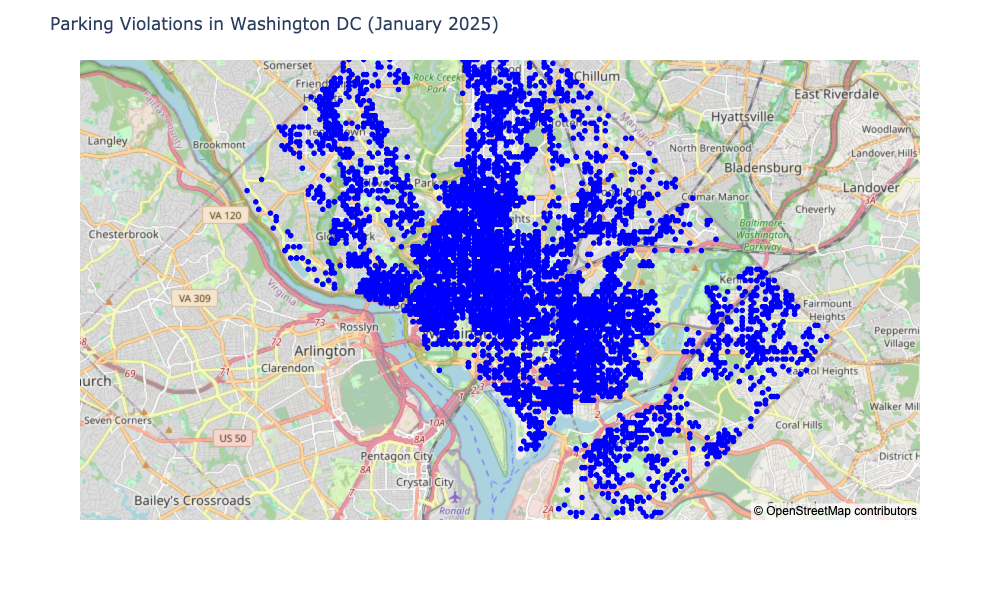

In [12]:
fig = px.scatter_mapbox(
    df,
    lat="LATITUDE",
    lon="LONGITUDE",
    hover_name="VIOLATION_PROC_DESC",
    hover_data=["ISSUE_DATE", "ISSUING_AGENCY_NAME", "LOCATION"],
    color_discrete_sequence=["blue"],
    zoom=11,
    height=600
)

fig.update_layout(
    mapbox_style="open-street-map",
    title="Parking Violations in Washington DC (January 2025)"
)
fig.write_html("parking_violations_map.html")
fig.show()


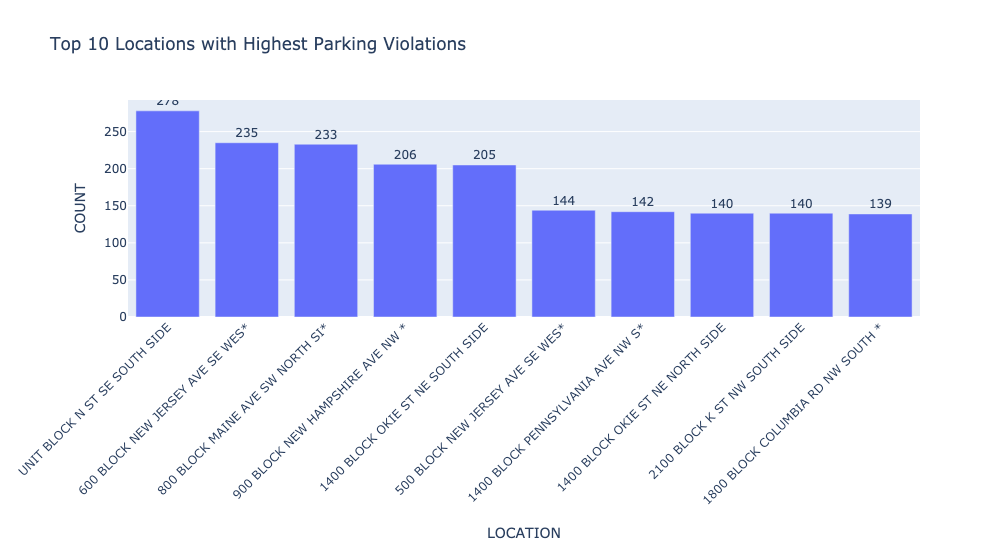

In [13]:
# Most common violation locations
location_counts = df['LOCATION'].value_counts().reset_index()
location_counts.columns = ['LOCATION', 'COUNT']
top_locations = location_counts.head(10)

# Plot
fig_location = px.bar(
    top_locations,
    x='LOCATION',
    y='COUNT',
    title='Top 10 Locations with Highest Parking Violations',
    text='COUNT'
)
fig_location.update_traces(textposition='outside')
fig_location.update_layout(xaxis_tickangle=-45)
fig_location.show()

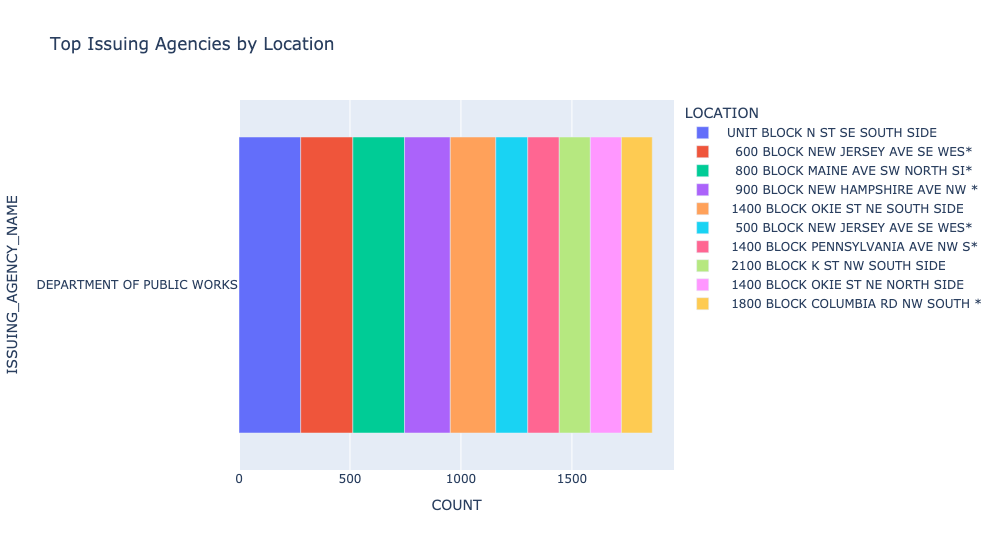

In [14]:
agency_location_counts = df.groupby(['ISSUING_AGENCY_NAME', 'LOCATION']).size().reset_index(name='COUNT')
top_agency_location = agency_location_counts.sort_values(by='COUNT', ascending=False).head(10)

# Plot
fig_agency_location = px.bar(
    top_agency_location,
    x='COUNT',
    y='ISSUING_AGENCY_NAME',
    color='LOCATION',
    title='Top Issuing Agencies by Location',
    orientation='h'
)
fig_agency_location.show()

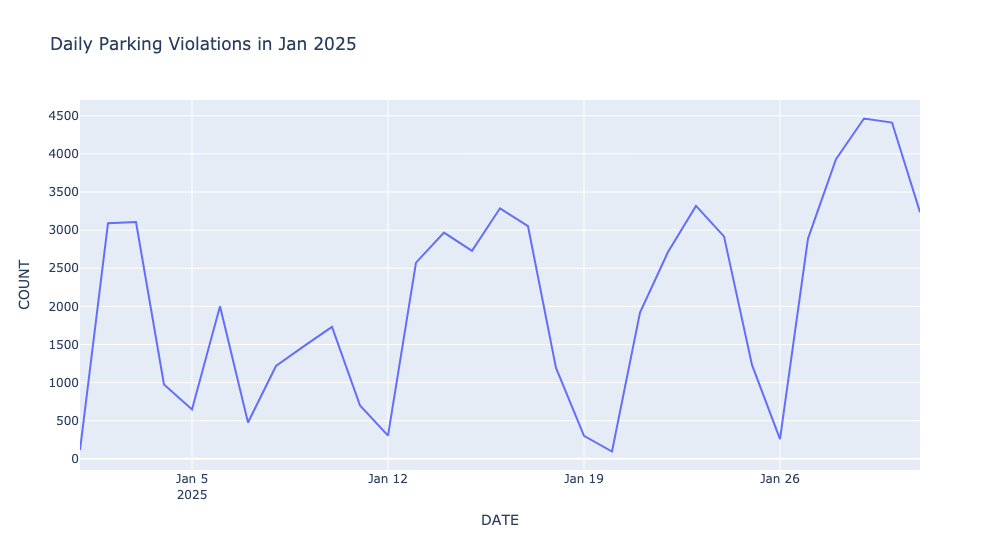

In [15]:
# Time Series - Daily Parking Violations
df['DATE'] = pd.to_datetime(df['ISSUE_DATE'], errors='coerce').dt.date
daily_violations = df.groupby('DATE').size().reset_index(name='COUNT')
fig_time_series = px.line(
    daily_violations,
    x='DATE',
    y='COUNT',
    title='Daily Parking Violations in Jan 2025'
)

fig_time_series.show()

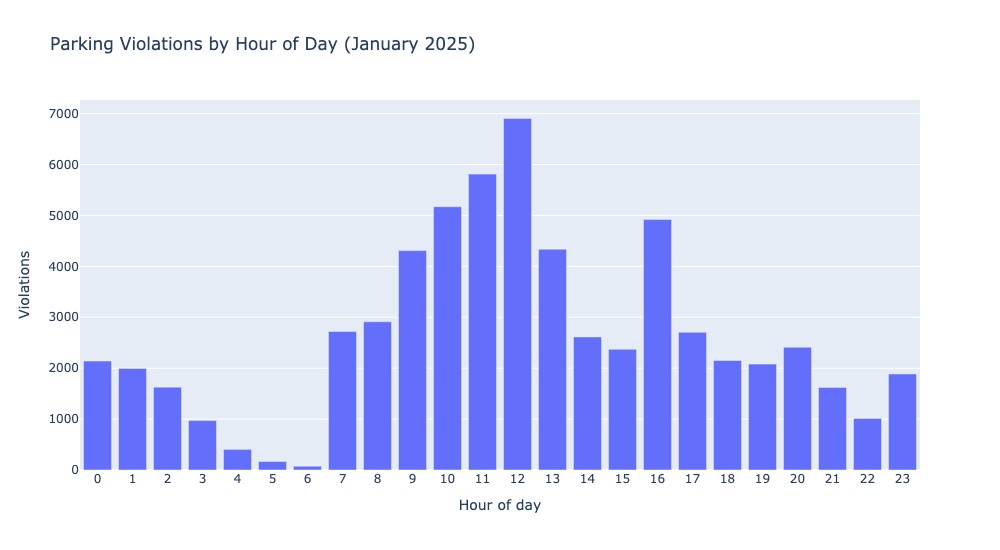

In [16]:
# Violations by hour of day (ISSUE_TIME is HHMM)
df['HOUR'] = (df['ISSUE_TIME'] // 100).astype(int)
hourly = df.groupby('HOUR').size().reindex(range(24), fill_value=0).reset_index(name='COUNT')
fig_hour = px.bar(hourly, x='HOUR', y='COUNT', title='Parking Violations by Hour of Day (January 2025)',
                  labels={'HOUR': 'Hour of day', 'COUNT': 'Violations'})
fig_hour.update_xaxes(dtick=1)
fig_hour.show()

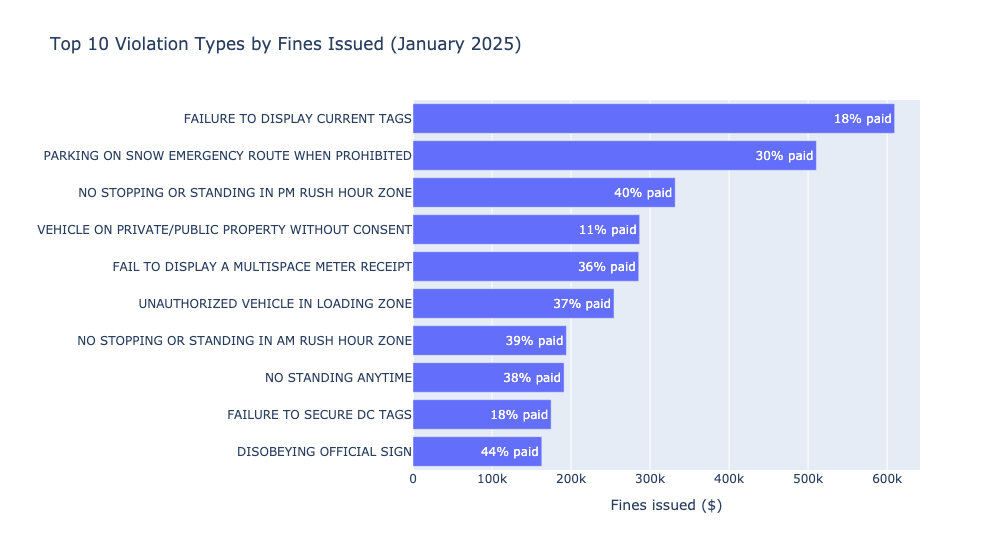

,TICKETS,FINES_ISSUED,PAID,PAID_SHARE
VIOLATION_PROC_DESC,,,,
FAILURE TO DISPLAY CURRENT TAGS,6097,609530,107660,0.176628
PARKING ON SNOW EMERGENCY ROUTE WHEN PROHIBITED,2042,510500,153860,0.301391
NO STOPPING OR STANDING IN PM RUSH HOUR ZONE,3318,331800,132845,0.400377
VEHICLE ON PRIVATE/PUBLIC PROPERTY WITHOUT CONSENT,1140,286800,30250,0.105474
FAIL TO DISPLAY A MULTISPACE METER RECEIPT,5714,285700,103975,0.363931
UNAUTHORIZED VEHICLE IN LOADING ZONE,2544,254400,93900,0.369104
NO STOPPING OR STANDING IN AM RUSH HOUR ZONE,1941,194100,75300,0.387944
NO STANDING ANYTIME,3824,191200,71975,0.376438
FAILURE TO SECURE DC TAGS,1748,174800,31550,0.180492


In [17]:
# Which violation types generate the most fines, and how much of it is paid?
fines = (df.groupby('VIOLATION_PROC_DESC')
           .agg(TICKETS=('TICKET_NUMBER', 'count'), FINES_ISSUED=('FINE_AMOUNT', 'sum'), PAID=('TOTAL_PAID', 'sum'))
           .sort_values('FINES_ISSUED', ascending=False).head(10))
fines['PAID_SHARE'] = fines['PAID'] / fines['FINES_ISSUED']

fig_fines = px.bar(fines.reset_index().iloc[::-1], x='FINES_ISSUED', y='VIOLATION_PROC_DESC', orientation='h',
                   text=fines.iloc[::-1]['PAID_SHARE'].map('{:.0%} paid'.format),
                   title='Top 10 Violation Types by Fines Issued (January 2025)',
                   labels={'FINES_ISSUED': 'Fines issued ($)', 'VIOLATION_PROC_DESC': ''})
fig_fines.update_layout(height=550, margin=dict(l=380))
fig_fines.show()
fines

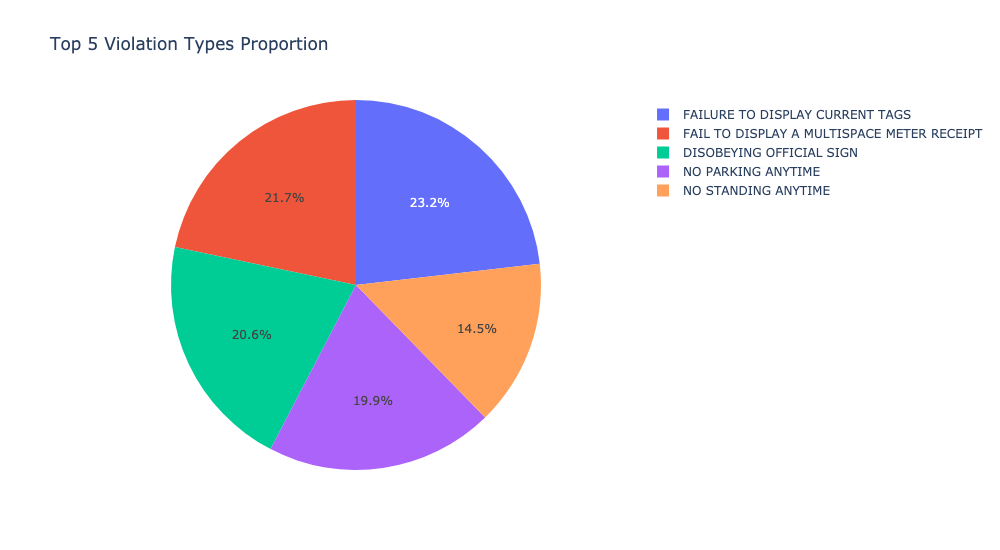

In [18]:
# Pie Chart - Top 5 Violation Types
top_violation_types = df['VIOLATION_PROC_DESC'].value_counts().nlargest(5)
fig_pie = px.pie(
    names=top_violation_types.index,
    values=top_violation_types.values,
    title='Top 5 Violation Types Proportion'
)

fig_pie.show()

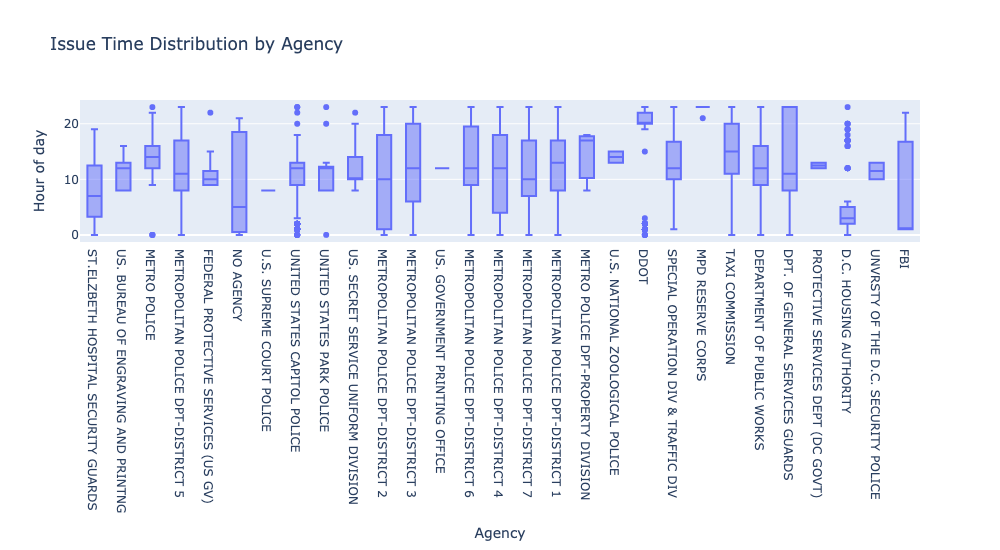

In [19]:
# Issue time distribution by agency (hour of day)
fig_box = px.box(df, x='ISSUING_AGENCY_NAME', y='HOUR', title='Issue Time Distribution by Agency',
                 labels={'HOUR': 'Hour of day', 'ISSUING_AGENCY_NAME': 'Agency'})
fig_box.show()

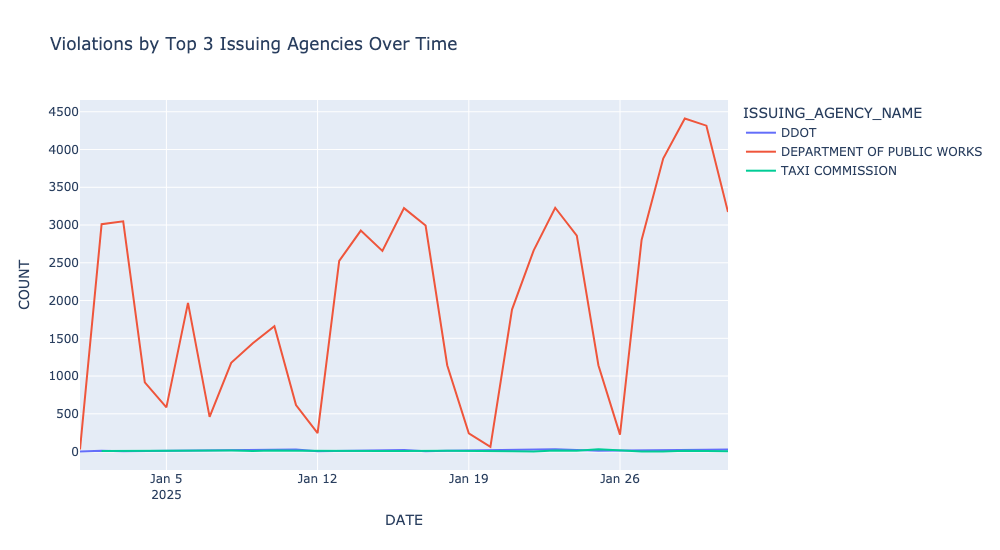

In [20]:
top_agencies = df['ISSUING_AGENCY_NAME'].value_counts().nlargest(3).index
df_agency = df[df['ISSUING_AGENCY_NAME'].isin(top_agencies)]

daily_agency_violations = df_agency.groupby(['DATE', 'ISSUING_AGENCY_NAME']).size().reset_index(name='COUNT')

fig_top_agencies = px.line(
    daily_agency_violations,
    x='DATE',
    y='COUNT',
    color='ISSUING_AGENCY_NAME',
    title='Violations by Top 3 Issuing Agencies Over Time'
)
fig_top_agencies.show()